<a href="https://colab.research.google.com/github/rinshadas141-web/Intel-Workshop/blob/main/Day_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
diabetes_path = "/content/diabetes.csv"

In [ ]:
diabetes_columns = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetespedigreeFunction",
    "Age",
    "Outcome"
]

In [ ]:
diabetes = pd.read_csv(diabetes_path, names=diabetes_columns)

print("Diabetes dataset loaded successfully.")

Diabetes dataset loaded successfully.


In [ ]:
diabetes.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetespedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
diabetes.tail()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetespedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


In [ ]:
print("Rows:", diabetes.shape[0])
print("Columns:", diabetes.shape[1])

Rows: 768
Columns: 9


In [ ]:
print(diabetes.columns.tolist())

['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetespedigreeFunction', 'Age', 'Outcome']


In [ ]:
diabetes.dtypes

,0
Pregnancies,int64
Glucose,int64
BloodPressure,int64
SkinThickness,int64
Insulin,int64
BMI,float64
DiabetespedigreeFunction,float64
Age,int64
Outcome,int64


In [ ]:
diabetes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetespedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [ ]:
diabetes.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetespedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [ ]:
diabetes_input_columns = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetespedigreeFunction",
    "Age"
]

diabetes_target_column = "Outcome"

print("Input variables:", diabetes_input_columns)
print("Target variable:", diabetes_target_column)

Input variables: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetespedigreeFunction', 'Age']
Target variable: Outcome


In [ ]:
print("Duplicate rows:", diabetes.duplicated().sum())
diabetes = diabetes.drop_duplicates()

Duplicate rows: 0


In [ ]:
import numpy as np

invalid_zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

diabetes[invalid_zero_columns] = diabetes[invalid_zero_columns].replace(
    0,
    np.nan

)

In [ ]:
diabetes.isnull().sum()

,0
Pregnancies,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetespedigreeFunction,0
Age,0
Outcome,0


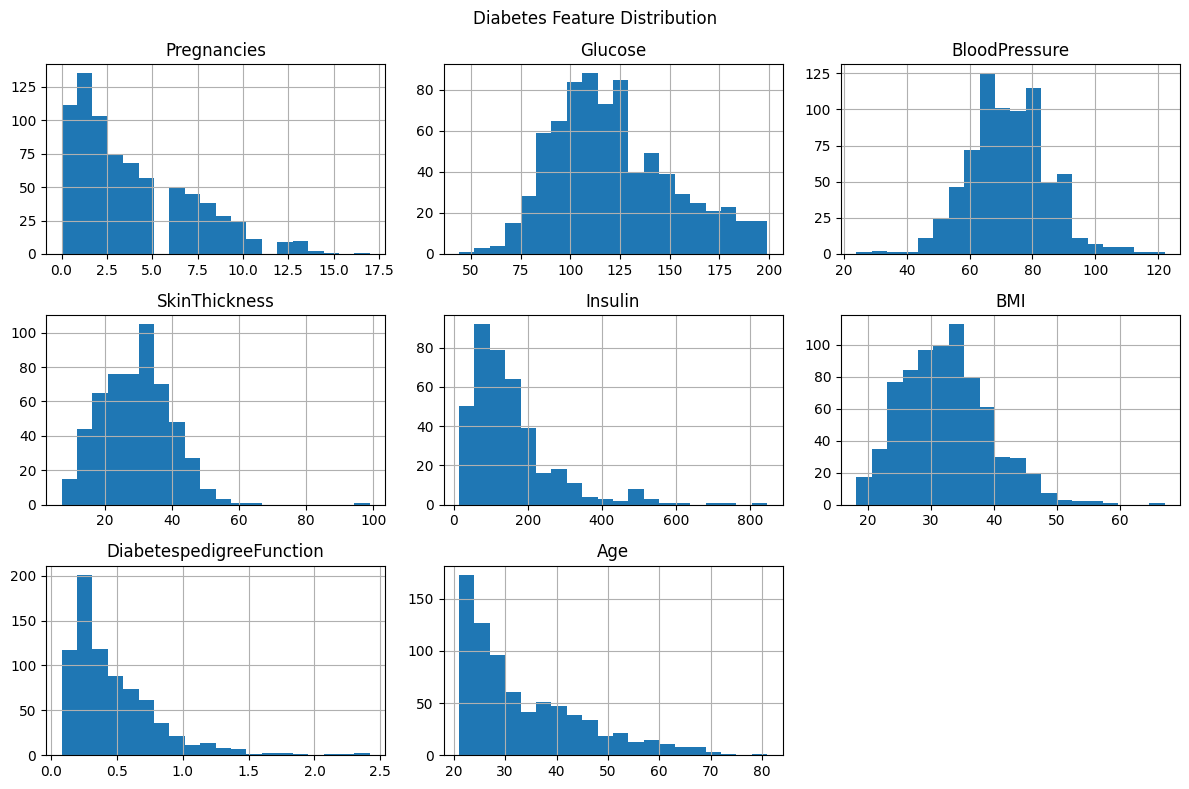

In [ ]:
import matplotlib.pyplot as plt

diabetes[diabetes_input_columns].hist(
    bins=20,
    figsize=(12, 8)
)

plt.suptitle("Diabetes Feature Distribution")
plt.tight_layout()
plt.show()

In [ ]:
diabetes[diabetes_input_columns].skew()

,0
Pregnancies,0.901674
Glucose,0.530989
BloodPressure,0.134153
SkinThickness,0.690619
Insulin,2.166464
BMI,0.593970
DiabetespedigreeFunction,1.919911
Age,1.129597


In [ ]:
for column in diabetes_input_columns:
  skew_value = diabetes[column].skew()

  if -0.5 <= skew_value <= 0.5:
    print(column, "-> Use mean")
  else:
    print(column, "-> Use median")

Pregnancies -> Use median
Glucose -> Use median
BloodPressure -> Use mean
SkinThickness -> Use median
Insulin -> Use median
BMI -> Use median
DiabetespedigreeFunction -> Use median
Age -> Use median


In [ ]:
diabetes["Glucose"] = diabetes["Glucose"].fillna(diabetes["Glucose"].median())
diabetes["BloodPressure"] = diabetes["BloodPressure"].fillna(diabetes["BloodPressure"].mean())
diabetes["SkinThickness"] = diabetes["SkinThickness"].fillna(diabetes["SkinThickness"].median())
diabetes["Insulin"] = diabetes["Insulin"].fillna(diabetes["Insulin"].median())
diabetes["BMI"] = diabetes["BMI"].fillna(diabetes["BMI"].median())

In [ ]:
diabetes.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetespedigreeFunction,0
Age,0
Outcome,0


In [ ]:
diabetes["Outcome"].value_counts()

,count
Outcome,
0,500
1,268


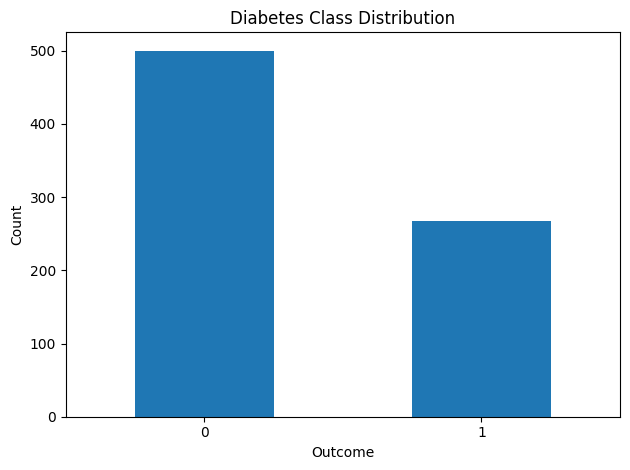

In [ ]:
diabetes["Outcome"].value_counts().plot(kind="bar")
plt.title("Diabetes Class Distribution")
plt.xlabel("Outcome")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
x_diabetes = diabetes.drop(
    "Outcome",
    axis=1
)
y_diabetes = diabetes["Outcome"]

In [ ]:
from sklearn.model_selection import train_test_split

x_train_diabetes, x_test_diabetes, y_train_diabetes, y_test_diabetes = train_test_split(
    x_diabetes,
    y_diabetes,
    test_size=0.20,
    random_state=42,
    stratify=y_diabetes
)

print("Training rows:", x_train_diabetes.shape[0])
print("Testing rows:", x_test_diabetes.shape[0])

Training rows: 614
Testing rows: 154


In [ ]:
from sklearn.tree import DecisionTreeClassifier

decision_tree = DecisionTreeClassifier(
  max_depth=4,
  class_weight="balanced",
  random_state=42
)

In [ ]:
decision_tree.fit(x_train_diabetes, y_train_diabetes)

print("Decision Tree model trained successfully.")

Decision Tree model trained successfully.


In [ ]:
diabetes_predictions = decision_tree.predict(x_test_diabetes)


In [ ]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

accuracy = accuracy_score(
    y_test_diabetes,
    diabetes_predictions
    )

print("Accuracy:", accuracy)
print("\nconfusion Matrix:")
print(confusion_matrix(y_test_diabetes, diabetes_predictions))
print("\nClassification Report:")
print(classification_report(y_test_diabetes, diabetes_predictions))

Accuracy: 0.7077922077922078

confusion Matrix:
[[64 36]
 [ 9 45]]

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.64      0.74       100
           1       0.56      0.83      0.67        54

    accuracy                           0.71       154
   macro avg       0.72      0.74      0.70       154
weighted avg       0.76      0.71      0.71       154



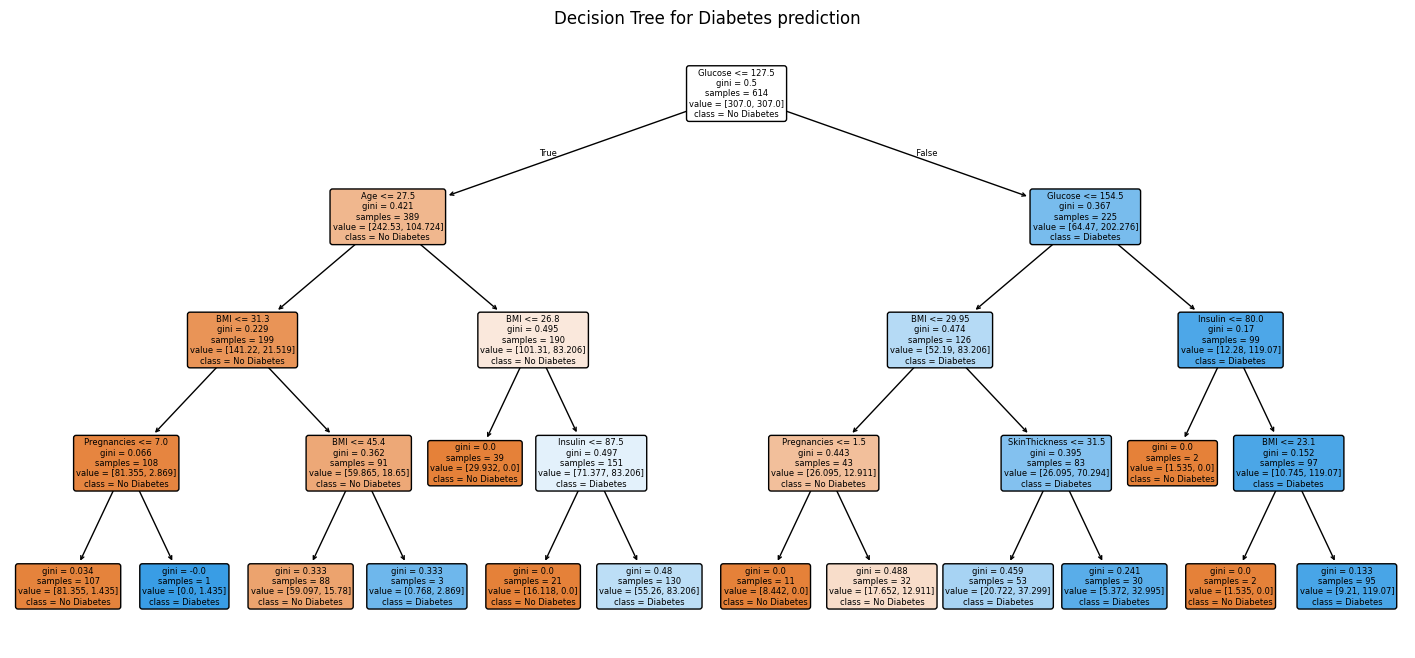

In [ ]:
from sklearn.tree import plot_tree

plt.figure(figsize=(18, 8))

plot_tree(
    decision_tree,
    feature_names=diabetes_input_columns,
    class_names=["No Diabetes", "Diabetes"],
    filled=True,
    rounded=True
)
plt.title("Decision Tree for Diabetes prediction")
plt.show()